### Importing Required Libraries

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd


import matplotlib.pyplot as plt
import seaborn as sns

# Make plots look cleaner
plt.style.use("ggplot")

# Download Financial Dataset
import yfinance as yf

# Machine Learning Utilities
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor

# Time Series Models
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Diagnostic Tests
from statsmodels.stats.diagnostic import acorr_ljungbox

# QQ Plot
from scipy import stats

# Save Model
import pickle

In [2]:
#Setting Random Seed

# Using a fixed random seed helps make results reproducible.
np.random.seed(42)

In [3]:
# Assignment Constants

# Training ends at December 2019
TRAIN_END = "2019-12"

# Testing starts from January 2020
TEST_START = "2020-01"

# Dictionary to store all model predictions
results = {}

In [4]:
#Creating Metric Function

def rmse(actual, predicted):
    """
    Calculate Root Mean Squared Error (RMSE)

    Parameters
    ----------
    actual : True values
    predicted : Predicted values

    Returns
    -------
    float
        RMSE value
    """

    actual = np.array(actual)
    predicted = np.array(predicted)

    return np.sqrt(np.mean((actual - predicted) ** 2))

### Downloading & Preparing Dataset

In [5]:
# Downloading monthly adjusted closing prices
raw = yf.download(
    "^GSPC",
    start="1990-01-01",
    end="2024-12-31",
    interval="1mo",
    auto_adjust=True,
    progress=False
)

# Display first few rows
raw.head()

Price,Close,High,Low,Open,Volume
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC
Date,,,,,
1990-01-01,329.079987,360.589996,319.829987,353.399994,3793250000
1990-02-01,331.890015,336.089996,322.100006,329.079987,2961970000
1990-03-01,339.940002,344.489990,331.079987,331.890015,3283280000
1990-04-01,330.799988,347.299988,327.760010,339.940002,2801220000
1990-05-01,361.230011,362.260010,330.799988,330.799988,3596680000


In [6]:
#Creating Time Series DataFrame

# Select only the Close column
series = raw["Close"].copy()

# Rename the series
series.name = "SP500"

# Remove timezone information (if present)
series.index = pd.to_datetime(series.index).tz_localize(None)

# Set the frequency to Month Start
series.index.freq = "MS"

# Display first five values
print(series.head())

Ticker           ^GSPC
Date                  
1990-01-01  329.079987
1990-02-01  331.890015
1990-03-01  339.940002
1990-04-01  330.799988
1990-05-01  361.230011


In [7]:
# Splitting into Training and Testing Data

train = series[:TRAIN_END]

test = series[TEST_START:]

print("Training Samples :", len(train))
print("Testing Samples  :", len(test))

Training Samples : 360
Testing Samples  : 60


In [8]:
# Log Transformation

log_train = np.log(train)

print(log_train.head())

Ticker         ^GSPC
Date                
1990-01-01  5.796301
1990-02-01  5.804804
1990-03-01  5.828769
1990-04-01  5.801514
1990-05-01  5.889515


In [9]:
#  Dataset Information

print("Index Data Type :", series.index.dtype)
print("Index Frequency :", series.index.freq)
print("Total Observations :", len(series))

Index Data Type : datetime64[s]
Index Frequency : <MonthBegin>
Total Observations : 420


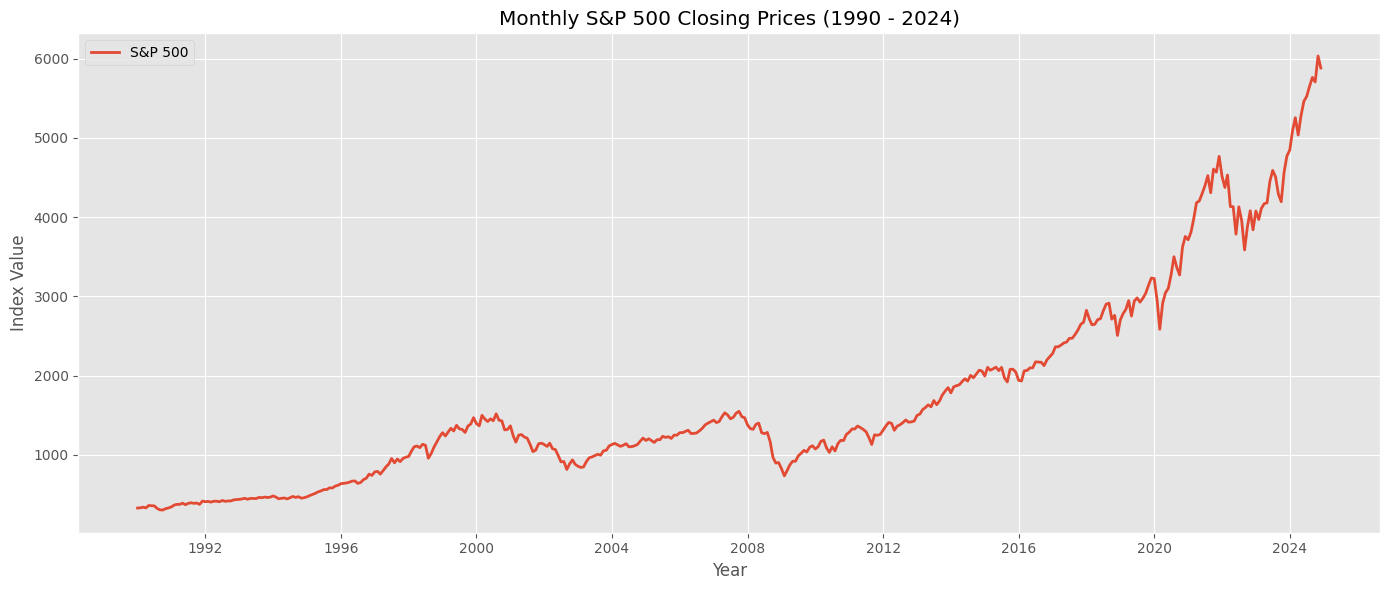

In [10]:
#Visualizing the Dataset

plt.figure(figsize=(14, 6))

plt.plot(
    series.index,
    series.values,
    linewidth=2,
    label="S&P 500"
)

plt.title("Monthly S&P 500 Closing Prices (1990 - 2024)")
plt.xlabel("Year")
plt.ylabel("Index Value")

plt.legend()

plt.tight_layout()
plt.show()

In [11]:
#Self Check

# Check DatetimeIndex
assert isinstance(series.index, pd.DatetimeIndex)

# Check frequency
assert str(series.index.freq) == "<MonthBegin>"

# Check dataset size
assert len(series) > 400

# Check train-test split
assert len(train) > len(test)

print("Q1 SELF-CHECK PASSED")

Q1 SELF-CHECK PASSED


## Q2: Quarterly Resampling

In [12]:
# Convert Monthly Data to Quarterly Data

# Take the last available price of every quarter
quarterly_series = series.resample("QE").last()

print("First 5 Quarterly Observations")
print(quarterly_series.head())

First 5 Quarterly Observations
Ticker           ^GSPC
Date                  
1990-03-31  339.940002
1990-06-30  358.019989
1990-09-30  306.049988
1990-12-31  330.220001
1991-03-31  375.220001


In [13]:
# Calculate Quarterly Percentage Returns

# Percentage change from previous quarter
quarterly_returns = quarterly_series.pct_change()

print("First 5 Quarterly Returns")
print(quarterly_returns.head())

First 5 Quarterly Returns
Ticker         ^GSPC
Date                
1990-03-31       NaN
1990-06-30  0.053186
1990-09-30 -0.145159
1990-12-31  0.078974
1991-03-31  0.136273


In [17]:
print(type(quarterly_series))
print(type(quarterly_returns))

print(quarterly_series.head())
print(quarterly_returns.head())

<class 'pandas.DataFrame'>
<class 'pandas.DataFrame'>
Ticker           ^GSPC
Date                  
1990-03-31  339.940002
1990-06-30  358.019989
1990-09-30  306.049988
1990-12-31  330.220001
1991-03-31  375.220001
Ticker         ^GSPC
Date                
1990-03-31       NaN
1990-06-30  0.053186
1990-09-30 -0.145159
1990-12-31  0.078974
1991-03-31  0.136273


In [19]:
quarterly_df = pd.DataFrame({
    "Price": quarterly_series,
    "Return": quarterly_returns
})

ValueError: If using all scalar values, you must pass an index

In [16]:
# Find Best Performing Decade

# Create a DataFrame
quarterly_df = pd.DataFrame({
    "Price": quarterly_series,
    "Return": quarterly_returns
})

# Extract year
quarterly_df["Year"] = quarterly_df.index.year

# Create decade column (1990, 2000, 2010, ...)
quarterly_df["Decade"] = (quarterly_df["Year"] // 10) * 10

# Average return for each decade
decade_returns = quarterly_df.groupby("Decade")["Return"].mean()

# Best decade
best_decade = decade_returns.idxmax()

print("Average Quarterly Return by Decade")
print(decade_returns)

print("\nBest Performing Decade:", best_decade)

ValueError: If using all scalar values, you must pass an index